# Download Rubin Variable-Star Alert Histories with VSX and Gaia Counterparts

## Workflow for time-series analysis and distance preparation

This notebook creates reusable local products from:

- **VSX:** identifiers, variable-star types, periods, and catalog metadata;
- **Rubin Alert Archive:** matched alerts and nested historical forced-source measurements;
- **Gaia DR3:** astrometry, parallaxes, proper motions, photometry, and quality indicators.

The workflow is:

```text
VSX variables
    ├── spatial match → Rubin alerts and alert histories
    └── spatial match → Gaia DR3 counterparts
```

It supports a small validation run and a full-sky run. Large results are written directly as local HATS catalogs rather than being collected into memory.

> VSX does not provide a homogeneous time series for every source. The time-domain measurements used here come from Rubin alert packets, especially `prvDiaForcedSources` when available. The public Rubin alert archive is a finite public sample, not the final ten-year alert stream.


## 1. Environment and imports

Run this notebook with the **Python (LINCC Rubin)** kernel.


In [1]:
import os
import sys
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nested_pandas as npd
import lsdb
import hats

from astropy.timeseries import LombScargle
from dask.distributed import Client

print("Python executable:", sys.executable)
print("Conda environment:", os.environ.get("CONDA_DEFAULT_ENV"))
print("Python:", sys.version.split()[0])
print("LSDB:", lsdb.__version__)
print("HATS:", hats.__version__)
print("nested-pandas:", npd.__version__)


Python executable: /Users/umbramortem/miniconda3/envs/lincc-rubin/bin/python
Conda environment: lincc-rubin
Python: 3.12.12
LSDB: 0.10.4
HATS: 0.10.4
nested-pandas: 0.6.10


## 2. Execution mode and output directory

Start with `MODE = "test"`. After the entire notebook succeeds, restart the kernel, change to `MODE = "full"`, and run again.


In [2]:
MODE = "test"  # Change to "full" only after the validation succeeds.

OUTPUT_ROOT = Path.home() / "lincc_variable_star_data"
RUBIN_PRODUCT_NAME = "vsx_rubin_alert_histories"
GAIA_PRODUCT_NAME = "vsx_gaia_counterparts"

RUBIN_OUTPUT = OUTPUT_ROOT / RUBIN_PRODUCT_NAME
GAIA_OUTPUT = OUTPUT_ROOT / GAIA_PRODUCT_NAME

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
usage = shutil.disk_usage(OUTPUT_ROOT)

print("Mode:", MODE)
print("Output directory:", OUTPUT_ROOT.resolve())
print(f"Free disk space: {usage.free / 1024**3:.1f} GiB")


Mode: test
Output directory: /Users/umbramortem/lincc_variable_star_data
Free disk space: 131.7 GiB


## 3. Start Dask

The defaults are conservative for a laptop with approximately 8–16 GB of RAM.


In [3]:
try:
    client.close()
except Exception:
    pass

client = Client(
    n_workers=2,
    threads_per_worker=1,
    memory_limit="2GB",
)
client


/Users/umbramortem/miniconda3/envs/lincc-rubin/lib/python3.12/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 52899 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:52899/status,
Dashboard: http://127.0.0.1:52899/status,Workers: 2
Total threads: 2,Total memory: 3.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:52900,Workers: 0
Dashboard: http://127.0.0.1:52899/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:52907,Total threads: 1
Dashboard: http://127.0.0.1:52909/status,Memory: 1.86 GiB
Nanny: tcp://127.0.0.1:52903,


2026-10-09 16:56:43,050 - distributed.scheduler - WARNING - Worker failed to heartbeat for 4481s; attempting restart: <WorkerState 'tcp://127.0.0.1:52907', name: 0, status: running, memory: 0, processing: 0>
2026-10-09 16:56:43,051 - distributed.scheduler - WARNING - Worker failed to heartbeat for 4481s; attempting restart: <WorkerState 'tcp://127.0.0.1:52908', name: 1, status: running, memory: 0, processing: 0>
2026-10-09 17:48:34,611 - distributed.scheduler - WARNING - Worker failed to heartbeat for 1450s; attempting restart: <WorkerState 'tcp://127.0.0.1:57176', name: 1, status: running, memory: 0, processing: 0>
2026-10-09 17:48:34,612 - distributed.scheduler - WARNING - Worker failed to heartbeat for 1450s; attempting restart: <WorkerState 'tcp://127.0.0.1:57177', name: 0, status: running, memory: 0, processing: 0>
Task was destroyed but it is pending!
task: <Task pending name='Task-7292501' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/umbramortem/mini

## 4. Remote catalog paths and test region

Gaia is accessed through the LSDB HTTPS mirror to avoid cloud-storage keyword incompatibilities.


In [4]:
VSX_PATH = "https://data.lsdb.io/hats/vsx/"
GAIA_PATH = "https://data.lsdb.io/hats/gaia_dr3/gaia/"
ALERTS_PATH = "https://data.lsdb.io/hats/rubin_alert_archive"

MATCH_RADIUS_ARCSEC = 1.0
TEST_CONE = lsdb.ConeSearch(
    52.98,
    -28.12,
    radius_arcsec=3600.0,
)


## 5. Inspect schemas and select columns

In [5]:
vsx_meta = lsdb.open_catalog(VSX_PATH)
gaia_meta = lsdb.open_catalog(GAIA_PATH)
alerts_meta = lsdb.open_catalog(ALERTS_PATH)

VSX_REQUESTED = [
    "OID", "Name", "VarFlag", "RAdeg", "DEdeg", "Type",
    "MagMax", "MaxPassband", "MagMin", "MinPassband",
    "Epoch", "Period", "SpectralType",
]
GAIA_REQUESTED = [
    "source_id", "ref_epoch", "ra", "dec",
    "parallax", "parallax_error", "parallax_over_error",
    "pmra", "pmra_error", "pmdec", "pmdec_error", "ruwe",
    "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag",
]
ALERT_REQUESTED = [
    "diaSourceId", "ra", "dec", "prvDiaSources", "prvDiaForcedSources",
]

vsx_columns = [c for c in VSX_REQUESTED if c in vsx_meta.columns]
gaia_columns = [c for c in GAIA_REQUESTED if c in gaia_meta.columns]
alert_columns = [c for c in ALERT_REQUESTED if c in alerts_meta.columns]

print("VSX columns:", vsx_columns)
print("Gaia columns:", gaia_columns)
print("Rubin alert columns:", alert_columns)


VSX columns: ['OID', 'Name', 'VarFlag', 'RAdeg', 'DEdeg', 'Type', 'MagMax', 'MaxPassband', 'MagMin', 'MinPassband', 'Epoch', 'Period', 'SpectralType']
Gaia columns: ['source_id', 'ref_epoch', 'ra', 'dec', 'parallax', 'parallax_error', 'parallax_over_error', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'ruwe', 'phot_g_mean_mag', 'phot_bp_mean_mag', 'phot_rp_mean_mag']
Rubin alert columns: ['diaSourceId', 'ra', 'dec', 'prvDiaForcedSources']


## 6. Open selected catalogs lazily

Test mode restricts the catalogs to a one-degree cone around ECDFS. Full mode applies no sky filter.


In [6]:
open_kwargs = {}
if MODE == "test":
    open_kwargs["search_filter"] = TEST_CONE

vsx = lsdb.open_catalog(VSX_PATH, columns=vsx_columns, **open_kwargs)
gaia = lsdb.open_catalog(GAIA_PATH, columns=gaia_columns, **open_kwargs)
alerts = lsdb.open_catalog(ALERTS_PATH, columns=alert_columns, **open_kwargs)

print(vsx)
print(gaia)
print(alerts)


lsdb Catalog 2026-10:
                               OID                   Name         VarFlag            RAdeg            DEdeg                   Type           MagMax            MaxPassband           MagMin            MinPassband            Epoch           Period           SpectralType
npartitions=1                                                                                                                                                                                                                                                              
Order: 0, Pixel: 8  int64[pyarrow]  large_string[pyarrow]  int64[pyarrow]  double[pyarrow]  double[pyarrow]  large_string[pyarrow]  double[pyarrow]  large_string[pyarrow]  double[pyarrow]  large_string[pyarrow]  double[pyarrow]  double[pyarrow]  large_string[pyarrow]
13 out of 21 available columns in the catalog have been loaded lazily, meaning no data has been read, only the catalog schema
This catalog has an estimated size of 19.1 MB
ls

## 7. Validate remote reads

Proceed only if all three previews succeed.


In [7]:
display(vsx.head(5))
display(gaia.head(5))
display(alerts.head(5))


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

,OID,Name,VarFlag,RAdeg,DEdeg,Type,MagMax,MaxPassband,MagMin,MinPassband,Epoch,Period,SpectralType
_healpix_29,,,,,,,,,,,,,
2528478682352289901,2894689,Gaia DR3 5056957338272473856,0,52.30729,-28.90523,ROT,18.05,G,18.17,G,<NA>,<NA>,<NA>
2528480266157691388,2894334,Gaia DR3 5056960503664636160,0,52.24225,-28.87815,ROT,15.04,G,15.09,G,<NA>,<NA>,M
2528480869384769464,2894210,Gaia DR3 5056961736318632320,0,52.22042,-28.82928,ROT,18.6,G,18.72,G,<NA>,2.17289,<NA>
2528541259764327373,2898460,Gaia DR3 5057082515095431680,0,52.98212,-29.11467,ROT,15.79,G,15.83,G,<NA>,<NA>,M
2528542016517128281,2898983,Gaia DR3 5057084026923915136,0,53.06977,-29.069,ROT,16.57,G,16.61,G,<NA>,6.1236,K


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

,source_id,ref_epoch,ra,dec,parallax,parallax_error,parallax_over_error,pmra,pmra_error,pmdec,pmdec_error,ruwe,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag
_healpix_29,,,,,,,,,,,,,,,
2528478166644625470,5056956311777326080,2016.0,52.33913,-28.939012,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,21.24593,20.845291,19.347668
2528478682346998320,5056957338272473856,2016.0,52.307449,-28.90524,4.073346,0.122007,33.386089,30.703969,0.08159,-2.835781,0.119537,1.036844,18.134504,19.843584,16.912119
2528478699685094287,5056957376927480832,2016.0,52.285389,-28.904382,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,21.004385,21.66342,19.728016
2528478711049714177,5056957406991951104,2016.0,52.300272,-28.896398,0.711557,0.49785,1.429259,2.150347,0.322343,2.734157,0.474239,1.066774,20.124313,21.075653,19.023399
2528480199073001807,5056960396289189248,2016.0,52.262845,-28.892603,1.183779,0.131804,8.981357,10.934982,0.087648,2.710204,0.134758,1.049687,18.313841,19.252707,17.357117


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

diaSourceId         ra        dec  \
_healpix_29                                                     
2528478682345737910  170107646612865083  52.307548 -28.905226   
2528478711039586141  170019696016359497  52.300518 -28.896263   
2528480307713372758  170068069954617387  52.253476 -28.877491   
2528480307801498296  170019696016359614  52.253158 -28.877506   
2528480724471019502  170019696149004351  52.219962  -28.85544   

                                                   prvDiaForcedSources  
_healpix_29                                                             
2528478682345737910                                                 []  
2528478711039586141  [{diaForcedSourceId: 170019696016359467, diaOb...  
2528480307713372758                                                 []  
2528480307801498296                                                 []  
2528480724471019502                                                 []

## 8. Prefer alerts with historical forced-source measurements

If the installed LSDB version cannot evaluate the nested-length query, all selected alerts are retained.


In [8]:
if "prvDiaForcedSources" in alert_columns:
    try:
        alerts_with_history = alerts.query("prvDiaForcedSources.len() > 0")
        print("Filtering to alerts with non-empty prvDiaForcedSources.")
    except Exception as error:
        warnings.warn(
            "Could not apply the nested-length query. Retaining all alerts. "
            + str(error)
        )
        alerts_with_history = alerts
else:
    warnings.warn("prvDiaForcedSources is not available in this alert schema.")
    alerts_with_history = alerts


Filtering to alerts with non-empty prvDiaForcedSources.


## 9. Build the VSX → Rubin nested crossmatch

Each output row represents one matched VSX source. Its matched Rubin rows are stored in a nested column named `rubin_alerts`.


In [9]:
try:
    vsx_rubin = vsx.crossmatch_nested(
        alerts_with_history,
        radius_arcsec=MATCH_RADIUS_ARCSEC,
        n_neighbors=None,
        nested_column_name="rubin_alerts",
        how="inner",
    )
except (TypeError, ValueError):
    warnings.warn(
        "This LSDB version rejected n_neighbors=None. "
        "Using n_neighbors=50 as a documented upper limit."
    )
    vsx_rubin = vsx.crossmatch_nested(
        alerts_with_history,
        radius_arcsec=MATCH_RADIUS_ARCSEC,
        n_neighbors=50,
        nested_column_name="rubin_alerts",
        how="inner",
    )

vsx_rubin


,OID,Name,VarFlag,RAdeg,DEdeg,Type,MagMax,MaxPassband,MagMin,MinPassband,Epoch,Period,SpectralType,rubin_alerts
npartitions=1,,,,,,,,,,,,,,
"Order: 1, Pixel: 35",int64[pyarrow],large_string[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],double[pyarrow],double[pyarrow],large_string[pyarrow],"nested<diaSourceId: [int64], ra: [double], dec..."


## 10. Build the VSX → Gaia counterpart catalog

Up to two Gaia neighbours are retained so ambiguous counterparts can be diagnosed later.


In [10]:
vsx_gaia = vsx.crossmatch(
    gaia,
    radius_arcsec=MATCH_RADIUS_ARCSEC,
    n_neighbors=2,
    how="inner",
    suffixes=("_vsx", "_gaia"),
)

vsx_gaia


/Users/umbramortem/miniconda3/envs/lincc-rubin/lib/python3.12/site-packages/lsdb/catalog/catalog.py:410: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(
/Users/umbramortem/miniconda3/envs/lincc-rubin/lib/python3.12/site-packages/lsdb/operations/functions/crossmatch_catalog_data.py:357: RuntimeWarning: Right catalog does not have a margin cache. Results may be incomplete and/or inaccurate.
  warnings.warn(


,OID_vsx,Name_vsx,VarFlag_vsx,RAdeg_vsx,DEdeg_vsx,Type_vsx,MagMax_vsx,MaxPassband_vsx,MagMin_vsx,MinPassband_vsx,Epoch_vsx,Period_vsx,SpectralType_vsx,source_id_gaia,ref_epoch_gaia,ra_gaia,dec_gaia,parallax_gaia,parallax_error_gaia,parallax_over_error_gaia,pmra_gaia,pmra_error_gaia,pmdec_gaia,pmdec_error_gaia,ruwe_gaia,phot_g_mean_mag_gaia,phot_bp_mean_mag_gaia,phot_rp_mean_mag_gaia,_dist_arcsec
npartitions=2,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 2, Pixel: 140",int64[pyarrow],large_string[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],double[pyarrow],double[pyarrow],large_string[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],double[pyarrow]
"Order: 2, Pixel: 141",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


## 11. Write local HATS products

This corrected write step disables optional summary and sky-map generation. Those decorative products can fail on a sparse test catalog because logarithmic density plotting has no valid positive range. The HATS data, metadata, Parquet metadata, and per-partition statistics are still written.

In test mode, partial outputs are removed first. In full mode, `resume=True` enables continuation after an interruption.


In [11]:
plt.close("all")

overwrite_products = MODE == "test"
resume_products = MODE == "full"

if MODE == "test":
    for product_path in [RUBIN_OUTPUT, GAIA_OUTPUT]:
        if product_path.exists():
            print("Removing previous test product:", product_path)
            shutil.rmtree(product_path)

common_write_options = {
    "overwrite": overwrite_products,
    "resume": resume_products,
    "progress_bar": True,
    "create_parquet_metadata": True,
    "create_per_partition_statistics": True,
    "create_summary": False,
    "create_thumbnail": False,
    "should_write_skymap": False,
}

print("Writing VSX × Rubin product...")
vsx_rubin.write_catalog(
    OUTPUT_ROOT,
    catalog_name=RUBIN_PRODUCT_NAME,
    **common_write_options,
)

print("Writing VSX × Gaia product...")
vsx_gaia.write_catalog(
    OUTPUT_ROOT,
    catalog_name=GAIA_PRODUCT_NAME,
    **common_write_options,
)

print("Rubin product:", RUBIN_OUTPUT.resolve())
print("Gaia product:", GAIA_OUTPUT.resolve())


Removing previous test product: /Users/umbramortem/lincc_variable_star_data/vsx_rubin_alert_histories
Writing VSX × Rubin product...


Writing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

Writing VSX × Gaia product...


Writing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

Rubin product: /Users/umbramortem/lincc_variable_star_data/vsx_rubin_alert_histories
Gaia product: /Users/umbramortem/lincc_variable_star_data/vsx_gaia_counterparts


## 12. Verify and reopen local products

In [20]:
print("Rubin product exists:", RUBIN_OUTPUT.exists())
print("Gaia product exists:", GAIA_OUTPUT.exists())

local_vsx_rubin = lsdb.open_catalog(RUBIN_OUTPUT)
local_vsx_gaia = lsdb.open_catalog(GAIA_OUTPUT)

print(local_vsx_rubin)
print(local_vsx_gaia)


Rubin product exists: True
Gaia product exists: True
lsdb Catalog vsx_rubin_alert_histories:
                                OID                   Name         VarFlag            RAdeg            DEdeg                   Type           MagMax            MaxPassband           MagMin            MinPassband            Epoch           Period           SpectralType                                                                                                                                                                                                                                                                                                                                                                                                                      rubin_alerts
npartitions=1                                                                                                                                                                                                               

In [21]:
rubin_sample = local_vsx_rubin.head(20)
gaia_sample = local_vsx_gaia.head(50)

display(rubin_sample.head())
display(gaia_sample.head())
print("Rubin nested columns:", list(local_vsx_rubin.nested_columns))


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

OID                          Name  VarFlag     RAdeg  \
_healpix_29                                                                     
2528634489801291617  2896659  Gaia DR3 5057268951036041216        0  52.65889   
2528649844333863396  2899187  Gaia DR3 5057299668642117376        0  53.10458   
2528704549707550133   252837      SSS 110224:033350-282244        0  53.45736   
2528711101883270239   178931     GUVV-2 J033339.3-281723.6        0  53.41375   
2528719485339226028  2903067  Gaia DR3 5057438963021199488        0   53.7858   

                        DEdeg  Type  MagMax MaxPassband  MagMin MinPassband  \
_healpix_29                                                                   
2528634489801291617  -29.0492     E    16.8           G   17.18           G   
2528649844333863396 -28.80922   VAR   15.62           G   15.65           G   
2528704549707550133 -28.37869  UGSU    14.4           V    18.6          CV   
2528711101883270239 -28.28989   VAR   19.65         NUV    0.81         NUV   
2528719485339226028 -28.14385   VAR    15.9           G    16.1           G   

                     Epoch    Period SpectralType  \
_healpix_29                                         
2528634489801291617   <NA>    1.2245            K   
2528649844333863396   <NA>  0.019117            G   
2528704549707550133   <NA>      <NA>         <NA>   
2528711101883270239   <NA>      <NA>         <NA>   
2528719485339226028   <NA>  0.014794            G   

                                                          rubin_alerts  
_healpix_29                                                             
2528634489801291617  [{diaSourceId: 170107646474453026, ra: 52.6589...  
2528649844333863396  [{diaSourceId: 170107645935484935, ra: 53.1046...  
2528704549707550133  [{diaSourceId: 170103251916029997, ra: 53.4573...  
2528711101883270239  [{diaSourceId: 170076861375185001, ra: 53.4139...  
2528719485339226028  [{diaSourceId: 170107646623875093, ra: 53.7858...

,OID_vsx,Name_vsx,VarFlag_vsx,RAdeg_vsx,DEdeg_vsx,Type_vsx,MagMax_vsx,MaxPassband_vsx,MagMin_vsx,MinPassband_vsx,Epoch_vsx,Period_vsx,SpectralType_vsx,source_id_gaia,ref_epoch_gaia,ra_gaia,dec_gaia,parallax_gaia,parallax_error_gaia,parallax_over_error_gaia,pmra_gaia,pmra_error_gaia,pmdec_gaia,pmdec_error_gaia,ruwe_gaia,phot_g_mean_mag_gaia,phot_bp_mean_mag_gaia,phot_rp_mean_mag_gaia,_dist_arcsec
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2528478682352289901,2894689,Gaia DR3 5056957338272473856,0,52.30729,-28.90523,ROT,18.05,G,18.17,G,<NA>,<NA>,<NA>,5056957338272473856,2016.0,52.307449,-28.90524,4.073346,0.122007,33.386089,30.703969,0.08159,-2.835781,0.119537,1.036844,18.134504,19.843584,16.912119,0.502678
2528480266157691388,2894334,Gaia DR3 5056960503664636160,0,52.24225,-28.87815,ROT,15.04,G,15.09,G,<NA>,<NA>,M,5056960503664636160,2016.0,52.242349,-28.87813,4.104852,0.050179,81.803757,20.408614,0.033781,3.603065,0.050802,2.321852,15.057244,16.135948,14.010532,0.319982
2528480869384769464,2894210,Gaia DR3 5056961736318632320,0,52.22042,-28.82928,ROT,18.6,G,18.72,G,<NA>,2.17289,<NA>,5056961736318632320,2016.0,52.220411,-28.829328,0.980645,0.158156,6.20049,-2.2808,0.106327,-11.251769,0.15399,0.990256,18.668615,19.889048,17.577068,0.17409
2528541259764327373,2898460,Gaia DR3 5057082515095431680,0,52.98212,-29.11467,ROT,15.79,G,15.83,G,<NA>,<NA>,M,5057082515095431680,2016.0,52.982181,-29.114879,3.295513,0.037264,88.436737,12.065662,0.026933,-47.248538,0.036891,1.268367,15.800004,17.006968,14.692563,0.77708
2528542016517128281,2898983,Gaia DR3 5057084026923915136,0,53.06977,-29.069,ROT,16.57,G,16.61,G,<NA>,6.1236,K,5057084026923915136,2016.0,53.069773,-29.069012,1.384641,0.046888,29.530632,-0.247125,0.033507,-3.27009,0.047859,1.010844,16.595547,17.361069,15.743599,0.04276


Rubin nested columns: ['rubin_alerts']


## 13. Helper functions for column normalization

In [22]:
def first_existing(columns, candidates, contains=None):
    columns = list(columns)
    for candidate in candidates:
        if candidate in columns:
            return candidate
    if contains is not None:
        matches = [c for c in columns if contains.lower() in str(c).lower()]
        if matches:
            return matches[0]
    return None


def normalize_gaia_crossmatch(frame):
    mapping = {}
    roles = {
        "vsx_oid": (["OID", "OID_vsx"], "OID"),
        "vsx_name": (["Name", "Name_vsx"], None),
        "vsx_type": (["Type", "Type_vsx"], None),
        "vsx_period": (["Period", "Period_vsx"], None),
        "gaia_source_id": (["source_id", "source_id_gaia"], None),
        "gaia_parallax": (["parallax", "parallax_gaia"], None),
        "gaia_parallax_error": (["parallax_error", "parallax_error_gaia"], None),
        "gaia_parallax_over_error": (["parallax_over_error", "parallax_over_error_gaia"], None),
        "gaia_ruwe": (["ruwe", "ruwe_gaia"], None),
        "gaia_g_mag": (["phot_g_mean_mag", "phot_g_mean_mag_gaia"], None),
        "gaia_bp_mag": (["phot_bp_mean_mag", "phot_bp_mean_mag_gaia"], None),
        "gaia_rp_mag": (["phot_rp_mean_mag", "phot_rp_mean_mag_gaia"], None),
        "vsx_gaia_dist_arcsec": (["_dist_arcsec"], "dist_arcsec"),
    }
    for target, (candidates, contains) in roles.items():
        source = first_existing(frame.columns, candidates, contains=contains)
        if source is not None:
            mapping[source] = target
    return frame.rename(columns=mapping), mapping


## 14. Choose the nearest Gaia counterpart in the preview

In [23]:
gaia_sample_norm, gaia_mapping = normalize_gaia_crossmatch(gaia_sample)
print("Column mapping:", gaia_mapping)

required = {"vsx_oid", "vsx_gaia_dist_arcsec"}
if not required.issubset(gaia_sample_norm.columns):
    raise KeyError("Could not identify VSX OID and Gaia crossmatch distance.")

gaia_best_sample = (
    gaia_sample_norm
    .sort_values(["vsx_oid", "vsx_gaia_dist_arcsec"], na_position="last")
    .drop_duplicates("vsx_oid", keep="first")
    .copy()
)

display(gaia_best_sample.head(20))


Column mapping: {'OID_vsx': 'vsx_oid', 'Name_vsx': 'vsx_name', 'Type_vsx': 'vsx_type', 'Period_vsx': 'vsx_period', 'source_id_gaia': 'gaia_source_id', 'parallax_gaia': 'gaia_parallax', 'parallax_error_gaia': 'gaia_parallax_error', 'parallax_over_error_gaia': 'gaia_parallax_over_error', 'ruwe_gaia': 'gaia_ruwe', 'phot_g_mean_mag_gaia': 'gaia_g_mag', 'phot_bp_mean_mag_gaia': 'gaia_bp_mag', 'phot_rp_mean_mag_gaia': 'gaia_rp_mag', '_dist_arcsec': 'vsx_gaia_dist_arcsec'}


,vsx_oid,vsx_name,VarFlag_vsx,RAdeg_vsx,DEdeg_vsx,vsx_type,MagMax_vsx,MaxPassband_vsx,MagMin_vsx,MinPassband_vsx,Epoch_vsx,vsx_period,SpectralType_vsx,gaia_source_id,ref_epoch_gaia,ra_gaia,dec_gaia,gaia_parallax,gaia_parallax_error,gaia_parallax_over_error,pmra_gaia,pmra_error_gaia,pmdec_gaia,pmdec_error_gaia,gaia_ruwe,gaia_g_mag,gaia_bp_mag,gaia_rp_mag,vsx_gaia_dist_arcsec
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2528480869384769464,2894210,Gaia DR3 5056961736318632320,0,52.22042,-28.82928,ROT,18.6,G,18.72,G,<NA>,2.17289,<NA>,5056961736318632320,2016.0,52.220411,-28.829328,0.980645,0.158156,6.20049,-2.2808,0.106327,-11.251769,0.15399,0.990256,18.668615,19.889048,17.577068,0.17409
2528480266157691388,2894334,Gaia DR3 5056960503664636160,0,52.24225,-28.87815,ROT,15.04,G,15.09,G,<NA>,<NA>,M,5056960503664636160,2016.0,52.242349,-28.87813,4.104852,0.050179,81.803757,20.408614,0.033781,3.603065,0.050802,2.321852,15.057244,16.135948,14.010532,0.319982
2528478682352289901,2894689,Gaia DR3 5056957338272473856,0,52.30729,-28.90523,ROT,18.05,G,18.17,G,<NA>,<NA>,<NA>,5056957338272473856,2016.0,52.307449,-28.90524,4.073346,0.122007,33.386089,30.703969,0.08159,-2.835781,0.119537,1.036844,18.134504,19.843584,16.912119,0.502678
2528641153725794744,2896298,Gaia DR3 5057282282614526080,0,52.59375,-28.94535,ROT,12.54,G,12.58,G,<NA>,<NA>,G,5057282282614526080,2016.0,52.593898,-28.945353,2.649194,0.010659,248.544739,29.823627,0.008065,-0.584855,0.010942,0.95843,12.571631,12.898049,12.087072,0.465381
2528634489801291617,2896659,Gaia DR3 5057268951036041216,0,52.65889,-29.0492,E,16.8,G,17.18,G,<NA>,1.2245,K,5057268951036041216,2016.0,52.658892,-29.049241,1.769302,0.05531,31.988998,0.313698,0.039356,-8.151317,0.055054,1.039852,16.842943,17.887463,15.831423,0.146394
2528644306496537083,2896933,Gaia DR3 5057288600510118784,0,52.71029,-28.88555,ROT,18.24,G,18.34,G,<NA>,0.436636,<NA>,5057288600510118784,2016.0,52.710332,-28.885547,1.381134,0.127058,10.870086,8.205796,0.094758,1.206027,0.13138,1.022223,18.298944,19.546659,17.223391,0.131884
2528647834216573103,2897058,Gaia DR3 5057295648552733824,0,52.73001,-28.68256,ROT,16.0,G,16.05,G,<NA>,<NA>,G,5057295648552733824,2016.0,52.729994,-28.682573,0.567523,0.032299,17.571108,-2.515038,0.02437,-3.879519,0.033921,1.019495,16.022692,16.357191,15.514837,0.067958
2528643986118218957,2897302,Gaia DR3 5057287951971346816,0,52.77423,-28.89425,ROT,18.04,G,18.12,G,<NA>,<NA>,<NA>,5057287951971346816,2016.0,52.77426,-28.89423,1.269272,0.115274,11.010943,6.151722,0.091441,5.279677,0.126674,1.081484,18.083248,19.154198,17.045031,0.118204
2528634083348063886,2897360,Gaia DR3 5057268160762053888,0,52.78368,-29.06971,ROT,15.74,G,15.77,G,<NA>,<NA>,K,5057268160762053888,2016.0,52.783735,-29.06971,1.833603,0.031164,58.837254,10.8163,0.022635,-0.071596,0.032271,1.030591,15.754857,16.485533,14.924797,0.173041


## 15. Extract Rubin forced-source histories

In [24]:
def nested_value_to_dataframe(value):
    if value is None:
        return pd.DataFrame()
    if isinstance(value, pd.DataFrame):
        return pd.DataFrame(value).copy()
    for method in ("to_pandas", "to_pylist", "tolist"):
        if hasattr(value, method):
            try:
                converted = getattr(value, method)()
                return converted.copy() if isinstance(converted, pd.DataFrame) else pd.DataFrame(converted)
            except Exception:
                pass
    try:
        return pd.DataFrame(value)
    except Exception:
        return pd.DataFrame()


def extract_rubin_history(source_row, history_field="prvDiaForcedSources"):
    alerts_table = nested_value_to_dataframe(source_row.get("rubin_alerts"))
    if alerts_table.empty or history_field not in alerts_table.columns:
        return pd.DataFrame()

    pieces = []
    for _, alert_row in alerts_table.iterrows():
        history = nested_value_to_dataframe(alert_row.get(history_field))
        if history.empty:
            continue
        for column in ["OID", "Name", "Type", "Period"]:
            if column in source_row.index:
                history[column] = source_row[column]
        history["parent_diaSourceId"] = alert_row.get("diaSourceId")
        pieces.append(history)

    if not pieces:
        return pd.DataFrame()

    result = pd.concat(pieces, ignore_index=True)
    id_column = first_existing(
        result.columns,
        ["diaForcedSourceId", "diaSourceId", "sourceId"],
    )
    if id_column is not None:
        result = result.drop_duplicates(id_column)
    return result


In [25]:
history_counts = []
for index, row in rubin_sample.iterrows():
    history = extract_rubin_history(row)
    history_counts.append((index, len(history)))

history_counts = sorted(history_counts, key=lambda item: item[1], reverse=True)
print("Largest histories in sample:", history_counts[:10])

if history_counts and history_counts[0][1] > 0:
    selected_index = history_counts[0][0]
    selected_source = rubin_sample.loc[selected_index]
    example_history = extract_rubin_history(selected_source)
    print("Selected history rows:", len(example_history))
    print("History columns:", example_history.columns.tolist())
    display(example_history.head())
else:
    example_history = pd.DataFrame()
    print("No non-empty forced-source history was found in this preview sample.")


Largest histories in sample: [(2528726319458660734, 12), (2529990927012520031, 11), (2528704549707550133, 8), (2530192124036613058, 8), (2530254345930749166, 7), (2528634489801291617, 1), (2528649844333863396, 1), (2528711101883270239, 1), (2528719485339226028, 1), (2528724742913875373, 1)]
Selected history rows: 12
History columns: ['diaForcedSourceId', 'diaObjectId', 'ra', 'dec', 'visit', 'detector', 'psfFlux', 'psfFluxErr', 'midpointMjdTai', 'scienceFlux', 'scienceFluxErr', 'band', 'timeProcessedMjdTai', 'timeWithdrawnMjdTai', 'OID', 'Name', 'Type', 'Period', 'parent_diaSourceId']


,diaForcedSourceId,diaObjectId,ra,dec,visit,detector,psfFlux,psfFluxErr,midpointMjdTai,scienceFlux,scienceFluxErr,band,timeProcessedMjdTai,timeWithdrawnMjdTai,OID,Name,Type,Period,parent_diaSourceId
0,170019696026845254,313879818524950547,53.964381,-27.905802,2026021600104,80,3.433696e+05,1561.195679,61088.097015,2592537.000,1499.740845,r,61088.098823,NaN,480394,SSS_J033551.6-275418,EB|EW,0.572112,170107646488608799
1,170019696157917189,313879818524950547,53.964381,-27.905802,2026021600105,74,6.727908e+05,1725.922729,61088.097446,2941504.500,1634.961548,r,61088.099229,NaN,480394,SSS_J033551.6-275418,EB|EW,0.572112,170107646488608799
2,170068070007046171,313879818524950547,53.964381,-27.905802,2026022700070,141,-6.797141e+05,1584.495117,61099.042416,2018704.000,1329.468018,i,61099.044198,NaN,480394,SSS_J033551.6-275418,EB|EW,0.572112,170107646488608799
3,170068070139691043,313879818524950547,53.964381,-27.905802,2026022700071,138,-8.292342e+05,1415.269165,61099.043207,1905304.625,1282.488892,i,61099.045181,NaN,480394,SSS_J033551.6-275418,EB|EW,0.572112,170107646488608799
4,170076861260890139,313879818524950547,53.964381,-27.905802,2026030100034,127,-1.458038e+06,2702.734863,61101.029450,1013756.250,910.816040,i,61101.031439,NaN,480394,SSS_J033551.6-275418,EB|EW,0.572112,170107646488608799


## 16. Identify time-series fields and plot an example

{'time': 'midpointMjdTai', 'band': 'band', 'flux': 'psfFlux', 'error': 'psfFluxErr'}


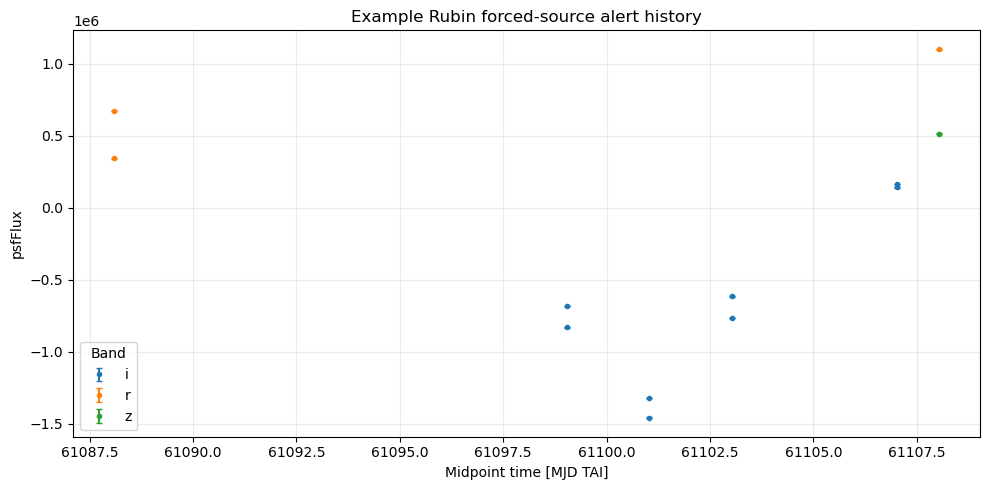

In [26]:
TIME_COLUMN = first_existing(
    example_history.columns,
    ["midpointMjdTai", "midpointMjd", "mjd", "time"],
)
BAND_COLUMN = first_existing(
    example_history.columns,
    ["band", "filter", "filterName"],
)
FLUX_COLUMN = first_existing(
    example_history.columns,
    ["psfFlux", "forcedPsfFlux", "diffimFlux", "flux"],
)
ERROR_COLUMN = first_existing(
    example_history.columns,
    ["psfFluxErr", "forcedPsfFluxErr", "diffimFluxErr", "fluxErr"],
)

print({
    "time": TIME_COLUMN,
    "band": BAND_COLUMN,
    "flux": FLUX_COLUMN,
    "error": ERROR_COLUMN,
})

if not example_history.empty and TIME_COLUMN is not None and FLUX_COLUMN is not None:
    example_history[TIME_COLUMN] = pd.to_numeric(example_history[TIME_COLUMN], errors="coerce")
    example_history[FLUX_COLUMN] = pd.to_numeric(example_history[FLUX_COLUMN], errors="coerce")
    if ERROR_COLUMN is not None:
        example_history[ERROR_COLUMN] = pd.to_numeric(example_history[ERROR_COLUMN], errors="coerce")

    example_history = example_history.dropna(subset=[TIME_COLUMN, FLUX_COLUMN]).copy()

    fig, ax = plt.subplots(figsize=(10, 5))
    groups = example_history.groupby(BAND_COLUMN) if BAND_COLUMN is not None else [("all", example_history)]

    for band, group in groups:
        group = group.sort_values(TIME_COLUMN)
        if ERROR_COLUMN is not None:
            ax.errorbar(
                group[TIME_COLUMN], group[FLUX_COLUMN], yerr=group[ERROR_COLUMN],
                fmt=".", capsize=2, label=str(band),
            )
        else:
            ax.plot(group[TIME_COLUMN], group[FLUX_COLUMN], ".", label=str(band))

    ax.set_xlabel("Midpoint time [MJD TAI]")
    ax.set_ylabel(FLUX_COLUMN)
    ax.set_title("Example Rubin forced-source alert history")
    ax.grid(alpha=0.25)
    ax.legend(title="Band")
    plt.tight_layout()
    plt.show()
else:
    print("No plottable forced-source history was found in the preview sample.")
